---
tags: [tutorial]
---

# QPE and Resource Estimation

Quantum Phase Estimation (QPE) is an algorithm that estimates the eigenphase $\phi$
associated with an eigenstate $|\psi\rangle$ of a unitary $U$:

$$
U|\psi\rangle=e^{2\pi i\phi}|\psi\rangle
$$

In this notebook, we first build the QPE circuit by hand and then compare it with
`qmc.qpe` from the Qamomile stdlib.

## 1. How QPE works

QPE uses two quantum registers with different roles.

- The **target register** holds the eigenstate $|\psi\rangle$ of $U$.
- The **counting register** consists of $n$ qubits and holds an $n$-bit
  approximation of the eigenphase. Its initial state is $|0\rangle^{\otimes n}$.

The mechanism that transfers the eigenphase from the target to the counting
register is phase kickback. Applying a controlled-$U$ with a single control in
$|+\rangle$ and the target in $|\psi\rangle$ gives

$$
\frac{|0\rangle|\psi\rangle+|1\rangle U|\psi\rangle}{\sqrt2}
=
\frac{|0\rangle+e^{2\pi i\phi}|1\rangle}{\sqrt2}|\psi\rangle
$$

The target returns to the same eigenstate, and only the eigenphase appears as a
relative phase on the control. QPE extends this operation to $n$ qubits and reads
out the phase in the following three stages.

### 1. Prepare a uniform superposition

Let $N=2^n$. We prepare $|\psi\rangle$ in the target and apply Hadamards to the
counting register. This gives a uniform superposition of the $N$ computational
basis states,

$$
|\Psi_1\rangle
=
\frac{1}{\sqrt N}
\sum_{y=0}^{N-1}|y\rangle|\psi\rangle.
$$

### 2. Accumulate the phase with controlled powers

Write the basis state as $y=\sum_{k=0}^{n-1}y_k2^k$. We apply $U^{2^k}$ to the
target, controlled by the $k$-th counting qubit. As a result,

$$
|\Psi_2\rangle
=
\frac{1}{\sqrt N}
\sum_{y=0}^{N-1}
e^{2\pi i\phi y}|y\rangle|\psi\rangle
$$

The information about $\phi$ is now recorded in the amplitudes.

### 3. Decode with the inverse QFT and measure

If $\phi=a/N$ can be represented with $n$ bits, the counting register is now in
the state $\operatorname{QFT}_N|a\rangle$. Applying the inverse QFT therefore gives

$$
|\Psi_3\rangle=|a\rangle|\psi\rangle
$$

Measuring the counting register yields the integer $a$, and the phase estimate is

$$
\widetilde{\phi}=\frac{a}{2^n}
$$

If $\phi$ cannot be represented exactly with $n$ bits, the measurement outcomes are
distributed around the closest values. Adding one more bit halves the phase
resolution $2^{-n}$, but it also doubles the largest power of the controlled
unitary.

### The example used in this notebook

We take the phase gate with $\theta=3\pi/4$, $P(\theta)|1\rangle=e^{i\theta}|1\rangle$,
as the unitary whose phase we want to estimate. The phase to be found is then
$\phi=\theta/(2\pi)=3/8=0.011_2$. Since this phase can be represented exactly with
3 qubits, QPE should return the computational basis state $|011\rangle$.

:::{note}
A general input $|\chi\rangle=\sum_jc_j|\psi_j\rangle$ contains several eigenstates.
When the eigenphases are distinct and exactly representable with the counting bits,
measuring the counting register gives $\phi_j$ with probability $|c_j|^2$ and projects
the target onto $|\psi_j\rangle$.
To keep the explanation simple, this notebook uses the known eigenstate $|1\rangle$.
:::

In [1]:
# Install Qamomile and the packages used in this notebook.
# !pip install "qamomile[qiskit,visualization]"

In [2]:
import math

import matplotlib.pyplot as plt
from qiskit_aer import AerSimulator

import qamomile.circuit as qmc
from qamomile.qiskit import QiskitTranspiler

SHOTS = 512
THETA = 3.0 * math.pi / 4.0
EXPECTED_PHASE = 3.0 / 8.0


@qmc.qkernel
def phase_gate(q: qmc.Qubit, theta: qmc.Float) -> qmc.Qubit:
    """Apply the phase $e^{i\\theta}$ to the eigenstate $|1\\rangle$."""
    return qmc.p(q, theta)

## 2. Build QPE by hand

We first defined the unitary that QPE receives as `phase_gate`. In Qamomile, the
unitary passed to QPE is also an ordinary qkernel. The phase gate in this example
implements

$$
P(\theta)|0\rangle=|0\rangle,\qquad
P(\theta)|1\rangle=e^{i\theta}|1\rangle
$$

If we prepare the target in $|1\rangle$, the eigenvalue is
$e^{i\theta}=e^{2\pi i\phi}$, so the phase returned by QPE is
$\phi=\theta/(2\pi)$.

In `manual_qpe` below, the QPE steps we saw above are mapped directly onto code.

1. Allocate the counting register with `qubit_array(n)` and the target register with `qubit()`
2. Prepare the target register in the eigenstate $|1\rangle$ with `x(target)`, and put the counting register into a superposition with `h(counting)`
3. Use `control(phase_gate)` to apply the unitary from each counting qubit with `power=2**k`
4. Decode the phase with `iqft(counting)`, cast it to `QFixed`, and then measure it


`QFixed` is the Qamomile type for treating a quantum register as a fixed-point
number. With `int_bits=0`, all $n$ qubits are interpreted as the fractional part, so
the integer $a$ after the inverse QFT is read out as the phase $a/2^n$.

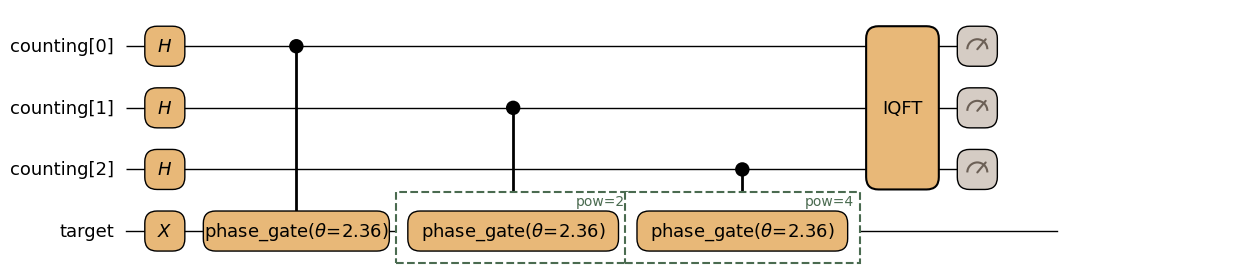

In [3]:
@qmc.qkernel
def manual_qpe(
    n: qmc.UInt,
    theta: qmc.Float,
) -> qmc.Float:
    """Build QPE from Hadamards, controlled powers, and an inverse QFT."""
    counting = qmc.qubit_array(n, "counting")
    target = qmc.qubit("target")

    target = qmc.x(target)
    counting = qmc.h(counting)

    controlled_phase = qmc.control(phase_gate)
    for k in qmc.range(n):
        counting[k], target = controlled_phase(
            counting[k],
            target,
            theta=theta,
            power=2**k,
        )

    counting = qmc.iqft(counting)
    phase = qmc.cast(counting, qmc.QFixed, int_bits=0)
    return qmc.measure(phase)


manual_qpe.draw(n=3, theta=THETA, fold_loops=False)

`qmc.control(phase_gate)` creates a controlled unitary from an existing qkernel.
This means there is no need to rewrite the unitary itself for QPE.

`power=2**k` realizes the operation "controlled-$U^{2^k}$".

The final `qmc.iqft(counting)` converts the phase pattern back into the integer $a$.
The following `qmc.cast(counting, qmc.QFixed, int_bits=0)` interprets the same
quantum register as the fixed-point number $a/2^n$. For example, for $|011\rangle$,

$$
\frac{1\cdot2^0+1\cdot2^1+0\cdot2^2}{2^3}
=\frac38
$$

`cast` reinterprets the register as a `QFixed` without adding gates. Measuring it returns a `Float`.

In [4]:
transpiler = QiskitTranspiler()
manual_executable = transpiler.transpile(
    manual_qpe,
    bindings={"n": 3, "theta": THETA},
)
manual_result = manual_executable.sample(
    transpiler.executor(),
    shots=SHOTS,
).result()
print("Manual QPE:", manual_result.results)

assert len(manual_result.results) == 1
manual_phase, manual_count = manual_result.results[0]
assert manual_count == SHOTS
assert math.isclose(manual_phase, EXPECTED_PHASE, abs_tol=1e-12)

Manual QPE: [(0.375, 512)]


Because $\phi=3/8$ can be represented exactly with 3 bits, every shot gives the same
phase value on a noiseless simulator. For a general phase, several nearby values
appear, so `sample_result.results` must be read as a distribution of measured values
and their counts.

## 3. The built-in `qmc.qpe`

Qamomile provides the same procedure as `qmc.qpe`. Building QPE by hand is well
suited to learning and understanding the circuit structure. When assembling more
complex algorithms, however, using the algorithms included in the stdlib makes even
complex algorithms easy to implement.

The first three arguments of `qmc.qpe` are:

- `target`: the target qubit or target register prepared in an eigenstate
- `counting`: the counting register in the initial state $|0\rangle^{\otimes n}$
- `phase_gate`: the unitary qkernel whose phase is to be estimated

The remaining keyword arguments are forwarded to the unitary. Here, `theta=theta`
becomes the parameter of `phase_gate`.

In the hand-built version we wrote `qmc.cast(..., qmc.QFixed, int_bits=0)`
explicitly, but `qmc.qpe` already includes the same conversion. Therefore, in both
implementations, the return value of `measure(phase)` is not a bit tuple but a
`Float` that has already been decoded to $a/2^n$.

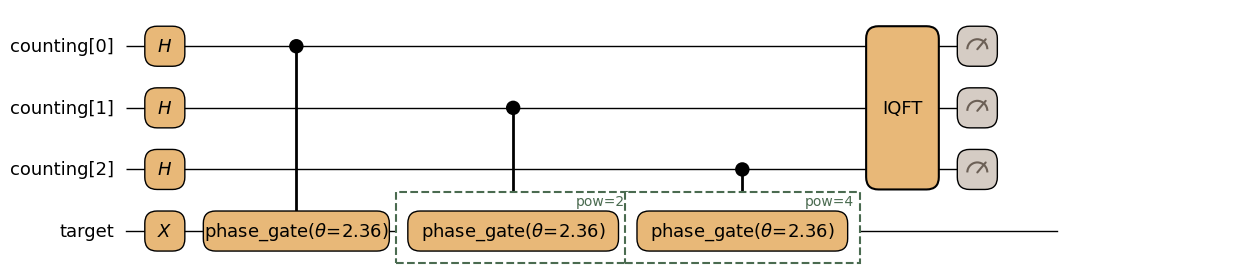

In [5]:
@qmc.qkernel
def builtin_qpe(
    n: qmc.UInt,
    theta: qmc.Float,
) -> qmc.Float:
    """Measure the phase as a fixed-point number with the Qamomile stdlib QPE."""
    counting = qmc.qubit_array(n, "counting")
    target = qmc.qubit("target")
    target = qmc.x(target)

    phase = qmc.qpe(target, counting, phase_gate, theta=theta)
    return qmc.measure(phase)


builtin_qpe.draw(n=3, theta=THETA, fold_loops=False)

In [6]:
builtin_executable = transpiler.transpile(
    builtin_qpe,
    bindings={"n": 3, "theta": THETA},
)
builtin_result = builtin_executable.sample(
    transpiler.executor(),
    shots=SHOTS,
).result()
print("Built-in QPE:", builtin_result.results)

assert len(builtin_result.results) == 1
builtin_phase, builtin_count = builtin_result.results[0]
assert math.isclose(builtin_phase, EXPECTED_PHASE, abs_tol=1e-12)
assert builtin_count == SHOTS

Built-in QPE: [(0.375, 512)]


## 4. Count logical resources from a concrete circuit

`estimate_resources()` does not execute a qkernel. It counts the number of logical
qubits and logical gates from the Qamomile IR. We first compare the hand-built and
built-in versions on the same 3-bit problem. If the values of the hand-built and
stdlib versions agree, we can confirm that the shorter notation is estimated to have
the same logical resource breakdown. Note, however, that having the same resource
breakdown does not mean that the transpiled circuits are completely
identical.

In [7]:
manual_resources = manual_qpe.estimate_resources(inputs={"n": 3, "theta": THETA})
builtin_resources = builtin_qpe.estimate_resources(inputs={"n": 3, "theta": THETA})

for name, resources in [
    ("manual", manual_resources),
    ("built-in", builtin_resources),
]:
    print(
        f"{name:8s}: qubits={resources.qubits}, "
        f"gates={resources.gates.total}, "
        f"two-qubit={resources.gates.two_qubit}"
    )

assert manual_resources.qubits == builtin_resources.qubits == 4
assert manual_resources.gates == builtin_resources.gates

manual  : qubits=4, gates=18, two-qubit=11
built-in: qubits=4, gates=18, two-qubit=11


## 5. Plug a variable-width Oracle into the built-in QPE

So far we have executed a concrete phase gate and counted resources from its
circuit. Sometimes, however, you want to study the scaling of the whole QPE before
a subroutine such as Hamiltonian simulation has been implemented. `qmc.Oracle` is an
abstract callable object that represents such an unimplemented unitary by its name
and signature alone.

In this section, we clearly separate the roles of the symbols.

- $n$: the number of qubits in the target register on which the unitary $U$ acts
- $m$: the number of qubits in the counting register, which estimates the phase with $m$ bits

In [8]:
oracle = qmc.Oracle(
    name="u",
    signature=qmc.CallableSignature(
        inputs=[qmc.Vector[qmc.Qubit]],
        outputs=[qmc.Vector[qmc.Qubit]],
    ),
)

In `CallableSignature`, we specify `Vector[Qubit] → Vector[Qubit]` rather than a
fixed number of qubits. This lets us reuse the same Oracle for different numbers of
qubits $n$.

Because the unitary passed to the built-in `qmc.qpe` must be a qkernel, we wrap the
Oracle in `u_for_qpe`, which contains only the Oracle call.

In [9]:
@qmc.qkernel
def u_for_qpe(
    target: qmc.Vector[qmc.Qubit],
) -> qmc.Vector[qmc.Qubit]:
    """Unitary qkernel that passes a variable-width Oracle to the built-in QPE."""
    return oracle(target)


@qmc.qkernel
def qpe_model(
    n: qmc.UInt,
    m: qmc.UInt,
) -> qmc.QFixed:
    """Build a symbolic resource model of QPE with a variable-width Oracle."""
    target = qmc.qubit_array(n, name="target")
    counting = qmc.qubit_array(m, name="counting")

    # In an actual QPE, the target would be prepared in an eigenstate of U here.
    return qmc.qpe(target, counting, u_for_qpe)

Because we give no concrete inputs to `estimate_resources()`, the result is an
algebraic expression in $n$ and $m$. In this example, the number of qubits is $m+n$.

In addition, since `qmc.qpe` calls controlled-$U^{2^k}$ for counting qubit $k$, in a
model that counts $U^{2^k}$ as $2^k$ queries to the base Oracle $U$, the number of
queries is

$$
1+2+\cdots+2^{m-1}=2^m-1
$$

With `UnknownResourcePolicy.OPAQUE_CALL`, Qamomile does not raise an error for an
Oracle without an implementation. Instead, it records the calls and queries by name.

We do not print `gates.total` here, so that it is not mistaken for the gate count of
the whole algorithm: it contains only the cost of the Hadamards and the inverse QFT
in QPE, and not the cost of the Oracle. Also, because this model has no Oracle body,
it cannot be transpiled and executed.

In [10]:
symbolic_resources = qpe_model.estimate_resources(
    unknown_policy=qmc.UnknownResourcePolicy.OPAQUE_CALL,
).simplify()

print("Symbolic qubits:", symbolic_resources.qubits)
print("Symbolic Oracle queries:", symbolic_resources.calls.oracle_queries)

Symbolic qubits: m + n
Symbolic Oracle queries: {'u': 2**m - 1}


We can see that the resource estimate is indeed what we expected.

Finally, we can also substitute values into this algebraic estimate to obtain
concrete numbers. This is a substitution into a formula, not a circuit construction,
so it can be computed quickly.

In [11]:
for n_value, m_value in [(2, 3), (4, 3), (4, 5)]:
    concrete = symbolic_resources.substitute(n=n_value, m=m_value)
    queries = int(concrete.calls.oracle_queries["u"])
    print(f"n={n_value}, m={m_value}: qubits={int(concrete.qubits)}, queries={queries}")
    assert int(concrete.qubits) == n_value + m_value
    assert queries == 2**m_value - 1

n=2, m=3: qubits=5, queries=7
n=4, m=3: qubits=7, queries=7
n=4, m=5: qubits=9, queries=31


## Exercise: A phase that cannot be represented with 3 bits

For this exercise, use a new angle `2*pi/3`, corresponding to $\phi=1/3$. Because this phase cannot be
represented exactly with 3 bits, several measurement outcomes appear. Increasing the
number of counting bits makes the phase resolution $2^{-n}$ finer, so confirm that
the peak of the distribution approaches $1/3$.

Specifically, investigate the following two points.

1. Compare the phase distributions for 3 and 5 counting bits
2. Increase the number of counting bits from 2 to 6 and confirm that the error between the most frequent value and $1/3$ decreases

In [12]:
# TODO: For theta=2*pi/3, examine the phase distribution and the error versus the number of counting bits.

### Example Solution

counting bits=2: peak=0.25000, error=0.08333
counting bits=3: peak=0.37500, error=0.04167
counting bits=4: peak=0.31250, error=0.02083


counting bits=5: peak=0.34375, error=0.01042


counting bits=6: peak=0.32812, error=0.00521


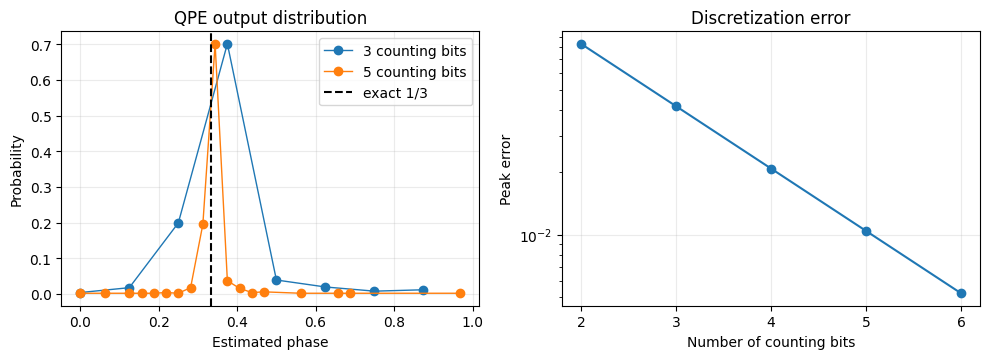

In [13]:
exercise_phase = 1.0 / 3.0
exercise_theta = 2.0 * math.pi * exercise_phase
counting_widths = [2, 3, 4, 5, 6]
phase_distributions = {}
peak_errors = {}

# Fix the simulator seed so the sampled histograms are reproducible.
exercise_executor = transpiler.executor(backend=AerSimulator(seed_simulator=42))

for counting_bits in counting_widths:
    exercise_executable = transpiler.transpile(
        builtin_qpe,
        bindings={"n": counting_bits, "theta": exercise_theta},
    )
    exercise_result = exercise_executable.sample(
        exercise_executor,
        shots=SHOTS,
    ).result()
    phase_distributions[counting_bits] = sorted(exercise_result.results)

    peak_phase, _ = max(exercise_result.results, key=lambda item: item[1])
    peak_errors[counting_bits] = abs(peak_phase - exercise_phase)
    print(
        f"counting bits={counting_bits}: "
        f"peak={peak_phase:.5f}, error={peak_errors[counting_bits]:.5f}"
    )

assert all(
    peak_errors[right] < peak_errors[left]
    for left, right in zip(counting_widths, counting_widths[1:], strict=False)
)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))

for counting_bits in [3, 5]:
    distribution = phase_distributions[counting_bits]
    phases = [phase for phase, _ in distribution]
    probabilities = [count / SHOTS for _, count in distribution]
    axes[0].plot(
        phases,
        probabilities,
        marker="o",
        linewidth=1,
        label=f"{counting_bits} counting bits",
    )

axes[0].axvline(exercise_phase, color="black", linestyle="--", label="exact 1/3")
axes[0].set(
    xlabel="Estimated phase",
    ylabel="Probability",
    title="QPE output distribution",
)
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(
    counting_widths,
    [peak_errors[width] for width in counting_widths],
    marker="o",
)
axes[1].set(
    xlabel="Number of counting bits",
    ylabel="Peak error",
    title="Discretization error",
    yscale="log",
)
axes[1].set_xticks(counting_widths)
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

## Summary

- In QPE, the target is prepared in an eigenstate (or a state with a large overlap with an eigenstate), and the counting qubits receive Hadamards, control the powers of $U$ on the target, and then undergo the inverse QFT.
- The Qamomile stdlib provides several algorithms, including QPE.
- The same qkernel can be used both to build an executable circuit and to estimate resources.
- Unimplemented subroutines can also be represented as an `Oracle`, and the number of Oracle queries can be estimated symbolically without assuming an implementation.

Adapted from the [QCE 2026 tutorial](https://github.com/Jij-Inc/Qamomile-QCE2026-Tutorial/blob/main/docs/tutorials/en/04_qpe_and_resource_estimation.ipynb).